# Binning and Discretization

**Binning** turns a continuous feature into a small number of intervals: age into age groups, income into bands. It can help linear models capture non-linear effects, makes models easier to explain, and reduces the influence of noise and outliers. It also throws information away; use it on purpose.

**After this lesson you can:**

1. Bin with equal-width, quantile, k-means and decision-tree boundaries.
2. Use binning (or splines) to let a linear model learn non-linear effects.
3. Compute weight of evidence (WoE) and information value (IV) as used in credit scoring.
4. Measure when binning helps and when it hurts.

**Data:** Adult census income.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

adult = datasets.adult()
y = (adult["income"] == ">50K").astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=RNG)

## 1. The Relationship Is Not Linear

The share of high earners rises with age until about 50 and then falls. A logistic regression on raw `age` can only model a monotonic (always rising or always falling) effect.

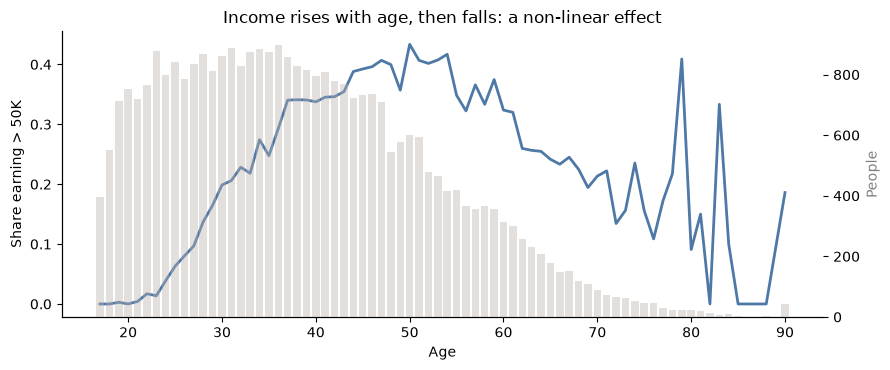

In [2]:
rate = y.groupby(adult["age"]).mean()
counts = adult["age"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(rate.index, rate.values, color="#4E79A7", lw=2)
ax.set(xlabel="Age", ylabel="Share earning > 50K", title="Income rises with age, then falls: a non-linear effect")
ax2 = ax.twinx()
ax2.bar(counts.index, counts.values, color="#BAB0AC", alpha=0.4)
ax2.set_ylabel("People", color="#7F7F7F")
plt.tight_layout()
plt.show()

## 2. Binning Strategies

| Strategy | Boundaries | Note |
| :--- | :--- | :--- |
| equal width | same width | sparse bins at the tails |
| quantile | same number of rows | robust to skew |
| k-means | 1-D clusters | follows the data's natural groups |
| decision tree | splits that best separate the target | supervised: fit inside cross-validation |

In [3]:
age = adult[["age"]]
results = {}
for s in ["uniform", "quantile", "kmeans"]:
    kb = KBinsDiscretizer(n_bins=6, encode="ordinal", strategy=s, subsample=None)
    results[s] = kb.fit(age).bin_edges_[0].round(1)
tree = DecisionTreeClassifier(max_leaf_nodes=6, min_samples_leaf=500, random_state=RNG).fit(age, y)
thr = sorted(t for t in tree.tree_.threshold if t > 0)
results["decision tree (supervised)"] = np.round([age["age"].min()] + thr + [age["age"].max()], 1)
for k, v in results.items():
    print(f"{k:<28} {v.tolist()}")

uniform                      [17.0, 29.2, 41.3, 53.5, 65.7, 77.8, 90.0]
quantile                     [17.0, 24.0, 31.0, 37.0, 44.0, 52.0, 90.0]
kmeans                       [17.0, 28.3, 38.2, 47.3, 56.3, 67.4, 90.0]
decision tree (supervised)   [17.0, 25.5, 29.5, 35.5, 43.5, 61.5, 90.0]


## 3. Does Binning Help a Linear Model?

The cell compares logistic regressions on `age` and `hours_per_week` with three representations: raw (scaled), one-hot bins, and **splines** (smooth piecewise polynomials, a modern alternative to bins).

{'raw (scaled)': np.float64(0.7988), 'quantile bins (10, one-hot)': np.float64(0.8177), 'splines (5 knots)': np.float64(0.8199)}


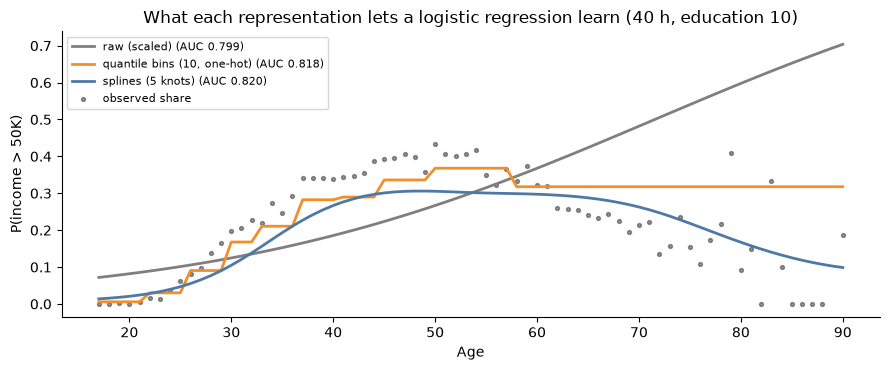

In [4]:
import warnings

# hours_per_week is exactly 40 for many people, so some quantile bins collapse to zero width;
# scikit-learn removes them and warns. The result is still correct, so the warning is silenced here.
warnings.filterwarnings("ignore", message="Bins whose width are too small")
X = adult[["age", "hours_per_week", "education_num"]]
reps = {
    "raw (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "quantile bins (10, one-hot)": make_pipeline(KBinsDiscretizer(10, encode="onehot", strategy="quantile", subsample=None),
                                                 LogisticRegression(max_iter=2000)),
    "splines (5 knots)": make_pipeline(SplineTransformer(n_knots=5, degree=3), LogisticRegression(max_iter=2000)),
}
scores = {k: cross_val_score(m, X, y, cv=cv, scoring="roc_auc").mean() for k, m in reps.items()}
print({k: round(v, 4) for k, v in scores.items()})

grid = pd.DataFrame({"age": np.arange(17, 91), "hours_per_week": 40, "education_num": 10})
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, m), c in zip(reps.items(), ["#7F7F7F", "#F28E2B", "#4E79A7"]):
    ax.plot(grid["age"], m.fit(X, y).predict_proba(grid)[:, 1], label=f"{name} (AUC {scores[name]:.3f})", color=c, lw=2)
ax.scatter(rate.index, rate.values, s=8, color="black", alpha=0.4, label="observed share")
ax.set(xlabel="Age", ylabel="P(income > 50K)", title="What each representation lets a logistic regression learn (40 h, education 10)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The raw linear model can only draw a monotonic S-curve; bins give a step function; splines give a smooth curve that rises and falls. Both bins and splines improve the AUC here because the true effect is non-linear. Tree models learn such effects without binning.

## 4. Weight of Evidence and Information Value

Credit scoring uses binned features with **weight of evidence**:

$$\text{WoE}_b = \ln \frac{\text{share of positives in bin } b}{\text{share of negatives in bin } b}, \qquad
\text{IV} = \sum_b (\text{pos}_b - \text{neg}_b)\,\text{WoE}_b$$

WoE puts each bin on a log-odds scale (easy to explain to regulators); IV summarises how predictive a feature is (rules of thumb: < 0.02 useless, 0.1–0.3 medium, > 0.3 strong).

In [5]:
def woe_table(x: pd.Series, y: pd.Series, bins: int = 6) -> tuple[pd.DataFrame, float]:
    b = pd.qcut(x, bins, duplicates="drop") if pd.api.types.is_numeric_dtype(x) else x.fillna("missing")
    t = pd.crosstab(b, y)
    pos, neg = t[1] / t[1].sum(), t[0] / t[0].sum()
    woe = np.log((pos + 1e-6) / (neg + 1e-6))
    iv = float(((pos - neg) * woe).sum())
    return pd.DataFrame({"rows": t.sum(axis=1), "positive_rate": (t[1] / t.sum(axis=1)).round(3), "WoE": woe.round(3)}), iv

table, iv_age = woe_table(adult["age"], y)
print(table, f"\nIV(age) = {iv_age:.3f}\n")
ivs = {c: woe_table(adult[c], y)[1] for c in ["age", "hours_per_week", "education_num", "marital_status", "occupation", "race", "sex"]}
print(pd.Series(ivs).sort_values(ascending=False).round(3).to_string())

                rows  positive_rate    WoE
age                                       
(16.999, 24.0]  5570          0.011 -3.355
(24.0, 31.0]    5890          0.137 -0.696
(31.0, 37.0]    5221          0.267  0.139
(37.0, 44.0]    5519          0.350  0.529
(44.0, 52.0]    4974          0.399  0.740
(52.0, 90.0]    5387          0.309  0.343 
IV(age) = 0.969

marital_status    1.339
age               0.969
occupation        0.776
education_num     0.608
hours_per_week    0.448
sex               0.303
race              0.069


`marital_status` (through "married") has the highest information value; `race` the lowest of the listed features. IV is a quick screening tool; it says nothing about fairness, which must be checked separately (M41).

*Insight: Bin when you need a linear, explainable model to capture non-linear effects, or when regulation requires grouped variables; fit supervised binning inside cross-validation. Prefer splines or tree models when interpretability by bins is not required.*

## Real-World Use Case or Analogy

Binning is like **grouping students by grade bands** (A, B, C) instead of exact percentages: simpler to communicate, robust to small differences, but two students with 89 % and 90 % end up in different bands.

Banks build credit scorecards from binned, WoE-encoded features because each bin's contribution to the score can be explained to a customer and a regulator ("points added for age 35–45").